# Level 3 — Task 3: NLP Sentiment Analysis

**Assignment objectives:** preprocess text using tokenization, stopword removal, and stemming or lemmatization; use NLTK or TextBlob for sentiment analysis; visualize sentiment distribution and word frequencies using word clouds.

**Dataset:** the supplied social-media sentiment dataset. Its provided `Sentiment` field contains many fine-grained emotion names (not just Positive, Negative, and Neutral). To meet the task's requested three-way polarity categories, this notebook uses TextBlob polarity from the actual post text to label each post Positive, Neutral, or Negative. The original label is retained for reference.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import RegexpTokenizer
from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from textblob import TextBlob
from wordcloud import WordCloud

## 1. Load the text data

In [2]:
data = pd.read_csv("data/social_media_sentiment.csv")
data = data.drop(columns=[c for c in data.columns if c.lower().startswith("unnamed")])
data["Text"] = data["Text"].fillna("").astype(str)

print("Rows:", len(data))
data[["Text", "Sentiment"]].head()

Rows: 732


,Text,Sentiment
0,Enjoying a beautiful day at the park! ...,Positive
1,Traffic was terrible this morning. ...,Negative
2,Just finished an amazing workout! 💪 ...,Positive
3,Excited about the upcoming weekend getaway! ...,Positive
4,Trying out a new recipe for dinner tonight. ...,Neutral


## 2. Tokenize, remove stopwords, and stem

NLTK's regular-expression tokenizer separates the text into word tokens. English stopwords are removed, and the Snowball stemmer reduces words to their stems. If the NLTK English stopword corpus is not installed locally, the notebook uses scikit-learn's built-in English stopword list as a fallback.

In [3]:
tokenizer = RegexpTokenizer(r"[A-Za-z]+")
stemmer = SnowballStemmer("english")

try:
    stop_words = set(stopwords.words("english"))
except LookupError:
    stop_words = set(ENGLISH_STOP_WORDS)

def preprocess_text(text):
    tokens = tokenizer.tokenize(str(text).lower())
    tokens = [word for word in tokens if word not in stop_words and len(word) > 1]
    stems = [stemmer.stem(word) for word in tokens]
    return stems

data["processed_tokens"] = data["Text"].apply(preprocess_text)
data["processed_text"] = data["processed_tokens"].apply(lambda tokens: " ".join(tokens))
data[["Text", "processed_text"]].head()

,Text,processed_text
0,Enjoying a beautiful day at the park! ...,enjoy beauti day park
1,Traffic was terrible this morning. ...,traffic terribl morn
2,Just finished an amazing workout! 💪 ...,just finish amaz workout
3,Excited about the upcoming weekend getaway! ...,excit upcom weekend getaway
4,Trying out a new recipe for dinner tonight. ...,tri new recip dinner tonight


## 3. Perform sentiment analysis with TextBlob

TextBlob returns a polarity score. Negative scores are labelled Negative, positive scores Positive, and exactly zero Neutral.

In [4]:
data["polarity"] = data["Text"].apply(lambda text: TextBlob(text).sentiment.polarity)

def polarity_label(score):
    if score > 0:
        return "Positive"
    if score < 0:
        return "Negative"
    return "Neutral"

data["predicted_sentiment"] = data["polarity"].apply(polarity_label)
data["predicted_sentiment"].value_counts()

predicted_sentiment
Neutral     324
Positive    282
Negative    126
Name: count, dtype: int64

## 4. Visualize sentiment distribution

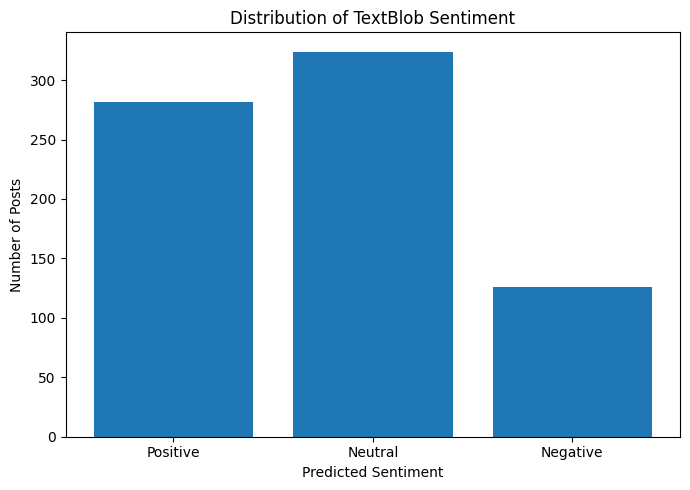

In [5]:
sentiment_order = ["Positive", "Neutral", "Negative"]
sentiment_counts = data["predicted_sentiment"].value_counts().reindex(sentiment_order, fill_value=0)
plt.figure(figsize=(7, 5))
plt.bar(sentiment_counts.index, sentiment_counts.values)
plt.title("Distribution of TextBlob Sentiment")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Number of Posts")
plt.tight_layout()
plt.show()

## 5. Visualize word frequencies using word clouds

Create one word cloud for each polarity group from the preprocessed, stemmed words.

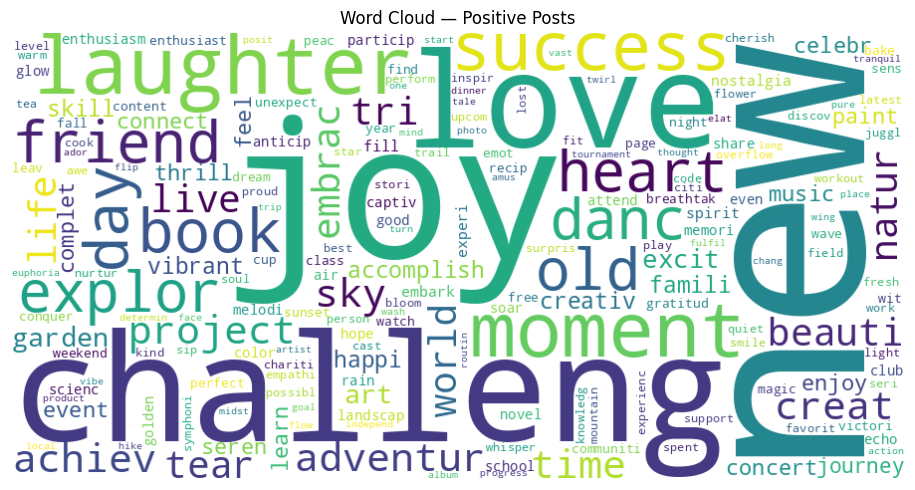

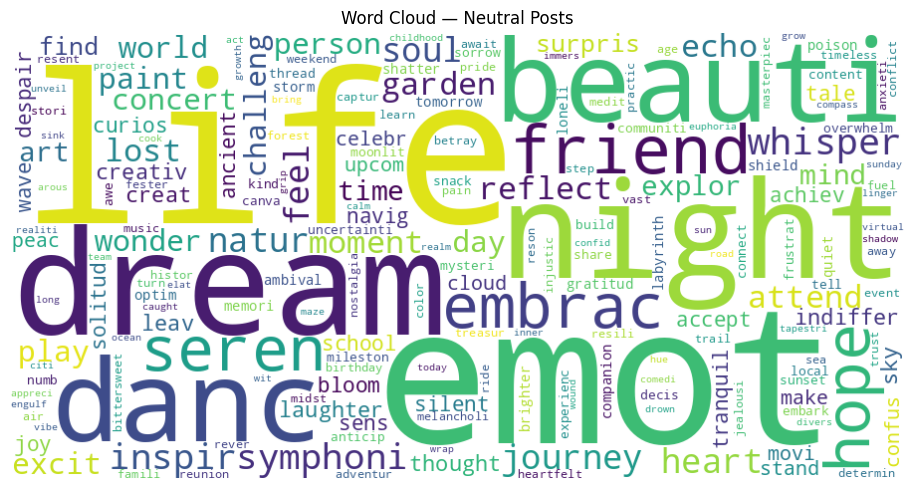

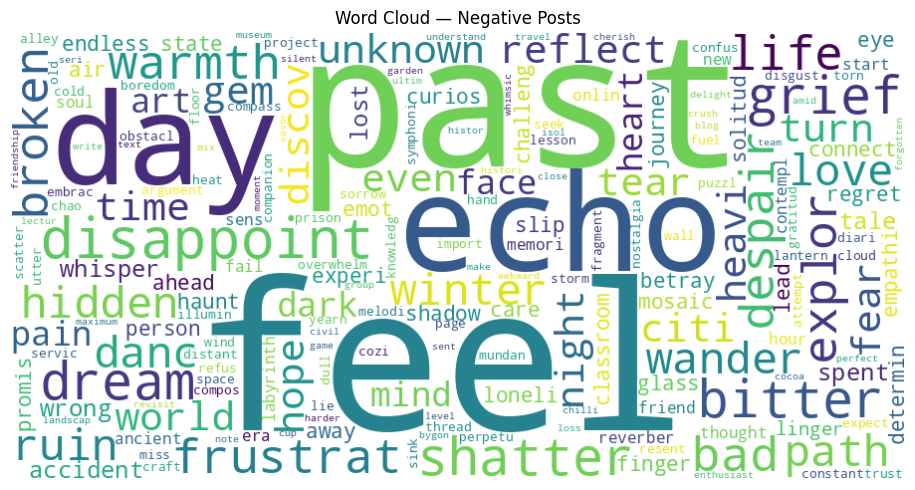

In [6]:
for sentiment in sentiment_order:
    text_for_cloud = " ".join(
        data.loc[data["predicted_sentiment"] == sentiment, "processed_text"]
    ).strip()

    if text_for_cloud:
        cloud = WordCloud(
            width=900,
            height=450,
            background_color="white",
            collocations=False
        ).generate(text_for_cloud)

        plt.figure(figsize=(10, 5))
        plt.imshow(cloud, interpolation="bilinear")
        plt.axis("off")
        plt.title(f"Word Cloud — {sentiment} Posts")
        plt.tight_layout()
        plt.show()

## Task 3 checklist

- [x] Tokenize text.
- [x] Remove stopwords.
- [x] Apply stemming.
- [x] Use TextBlob for sentiment analysis and classify posts as Positive, Neutral, or Negative.
- [x] Visualize sentiment distribution and word frequencies with word clouds.

**Interpretation note:** TextBlob is a lexicon-based sentiment analyzer. Its labels are predictions from text polarity, not verified ground-truth labels. The original dataset's `Sentiment` column has more than three emotion categories and is not used as the three-class polarity output.